In [1]:
import time
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.special import expit
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegressionCV, LassoCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict, StratifiedKFold

import seaborn as sns
from econml.dr import DRLearner, LinearDRLearner, SparseLinearDRLearner, ForestDRLearner

from econml.dml import DML, LinearDML, SparseLinearDML, CausalForestDML

# Helper imports
import numpy as np
from itertools import product
from sklearn.linear_model import (Lasso, MultiTaskElasticNetCV)
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from econml.dml import DML, LinearDML, SparseLinearDML, CausalForestDML, NonParamDML

# Importing dataset:

dataset = pd.read_stata(
    r"C:\Users\jonat\OneDrive\Desktop\Uni\Gerber et al 2008\GerberGreenLarimer_APSR_2008_social_pressure.dta",
    convert_categoricals=False
)

# Defining binary treatment and outcome variable:
dataset["D"] = (dataset["treatment"] != 0).astype(int)
dataset["Y"] = dataset["voted"]
X = ["sex", "g2000", "g2002", "p2000", "p2002", "p2004", "hh_size"]

# Selection parameters:
S = "yob"
alpha = 0.0
gamma = 1.0
seed = 1465

rng = np.random.default_rng(seed)

# Standardizing year of birth (biased variable):
S_std = (dataset[S] - dataset[S].mean()) / dataset[S].std()

# Treated = +1, Control = -1
sign = np.where(dataset["D"] == 1, 1, -1)

# Logistic selection probability:
u = alpha + gamma * sign * S_std
p_keep = expit(u)

# Constructing biased sample:
keep = rng.uniform(size=len(dataset)) < p_keep
biased = dataset.loc[keep].copy()

In [2]:
# LinearDML on full sample:

Y_full = dataset["Y"]
D_full = dataset["D"]
X_full = dataset[X]

est = LinearDML(model_y=RandomForestRegressor(),
                model_t=RandomForestRegressor(),
                discrete_treatment=True,
                random_state=123)
est.fit(Y_full, D_full, X=X_full)
te_pred = est.effect(X_full)

print(est.ate(X_full))
print(est.ate_interval(X_full, alpha=0.05))

C:\Users\jonat\anaconda3\Lib\site-packages\econml\dml\dml.py:51: UserWarning: First stage model has discrete target but model is not a classifier!
  warn('First stage model has discrete target but model is not a classifier!', UserWarning)
C:\Users\jonat\anaconda3\Lib\site-packages\econml\dml\dml.py:51: UserWarning: First stage model has discrete target but model is not a classifier!
  warn('First stage model has discrete target but model is not a classifier!', UserWarning)


0.042450642145166646
(np.float64(0.039439075277862605), np.float64(0.04546220901247069))


In [24]:
# LinearDML on biased sample:

Y_full_biased = biased["Y"]
D_full_biased = biased["D"]
X_full_biased = biased[X + ["yob"]]

est_biased = LinearDML(model_y=RandomForestRegressor(),
                model_t=RandomForestRegressor(),
                discrete_treatment=True,
                random_state=123)
est_biased.fit(Y_full_biased, D_full_biased, X=X_full_biased)
te_pred_biased = est_biased.effect(X_full_biased)

print(est_biased.ate(X_full_biased))
print(est_biased.ate_interval(X_full_biased, alpha=0.05))

C:\Users\jonat\anaconda3\Lib\site-packages\econml\dml\dml.py:51: UserWarning: First stage model has discrete target but model is not a classifier!
  warn('First stage model has discrete target but model is not a classifier!', UserWarning)
C:\Users\jonat\anaconda3\Lib\site-packages\econml\dml\dml.py:51: UserWarning: First stage model has discrete target but model is not a classifier!
  warn('First stage model has discrete target but model is not a classifier!', UserWarning)


0.040640222846143055
(np.float64(0.035882476073048127), np.float64(0.045397969619238025))


In [25]:
# NonparamDML on full sample:

Y_full = dataset["Y"]
D_full = dataset["D"]
X_full = dataset[X]

from econml.grf import RegressionForest

est_non = NonParamDML(model_y=RandomForestRegressor(),
                      model_t=RandomForestClassifier(),
                      model_final=RegressionForest(min_samples_leaf=50, random_state=123),
                      discrete_treatment=True,
                      random_state=123)
est_non.fit(Y_full, D_full, X=X_full)

print(est_non.ate(X_full))
print(est_non.ate_interval(X_full, alpha=0.05))

0.04310296898368969
(np.float64(0.007574771603297656), np.float64(0.07863116636408171))


In [26]:
# NonparamDML on biased sample:

Y_full_biased = biased["Y"]
D_full_biased = biased["D"]
X_full_biased = biased[X + ["yob"]]

est_non_biased = NonParamDML(model_y=RandomForestRegressor(),
                      model_t=RandomForestClassifier(),
                      model_final=RegressionForest(min_samples_leaf=50, random_state=123),
                      discrete_treatment=True,
                      random_state=123)
est_non_biased.fit(Y_full_biased, D_full_biased, X=X_full_biased)

print(est_non_biased.ate(X_full_biased))
print(est_non_biased.ate_interval(X_full_biased, alpha=0.05))

0.03989674803851383
(np.float64(-0.03765969463614627), np.float64(0.1174531907131739))


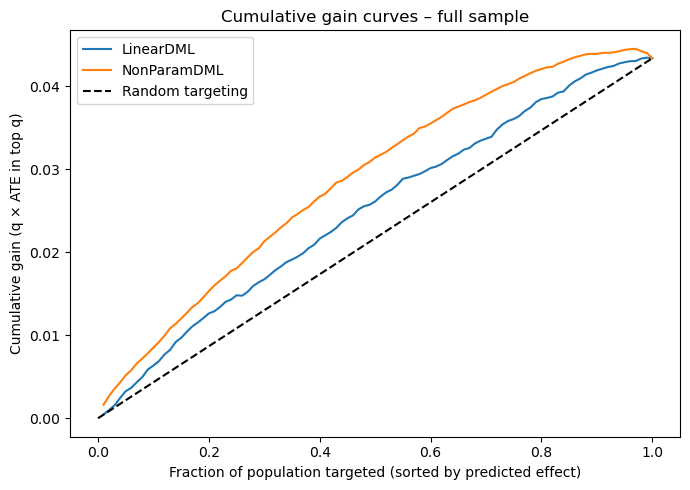

In [27]:
# Cumulative gain plot, full sample:

def cumulative_gain(tau_hat, Y, D, n_points=100):
    tau_hat = np.ravel(tau_hat)
    order = np.argsort(-tau_hat)
    Y_s = np.asarray(Y)[order]
    D_s = np.asarray(D)[order]
    n = len(Y_s)

    fracs = np.linspace(0.01, 1, n_points)
    gains = []
    for q in fracs:
        k = int(q * n)
        y, d = Y_s[:k], D_s[:k]
        ate_q = y[d == 1].mean() - y[d == 0].mean()
        gains.append(q * ate_q)
    return fracs, np.array(gains)

frac_lin, gain_lin = cumulative_gain(te_pred, Y_full, D_full)
frac_non, gain_non = cumulative_gain(te_pred_non, Y_full, D_full)

ate_all = Y_full[D_full == 1].mean() - Y_full[D_full == 0].mean()

plt.figure(figsize=(7, 5))
plt.plot(frac_lin, gain_lin, label="LinearDML")
plt.plot(frac_non, gain_non, label="NonParamDML")
plt.plot([0, 1], [0, ate_all], "k--", label="Random targeting")
plt.xlabel("Fraction of population targeted (sorted by predicted effect)")
plt.ylabel("Cumulative gain (q × ATE in top q)")
plt.title("Cumulative gain curves – full sample")
plt.legend()
plt.tight_layout()
plt.savefig("cumulative_gain_full.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
# Defining variables for table:

benchmark_est = 4.290
benchmark_ci_lower = 3.963
benchmark_ci_upper = 4.686

naive_est = -0.0085*100
naive_ci_lower = -0.0129*100
naive_ci_upper = -0.0040*100

psm_est = 5.00145
psm_ci_lower = 4.701
psm_ci_upper = 5.302

dr_with_s = 0.0427*100
dr_with_s_lower = 0.0397*100
dr_with_s_upper = 0.0457*100

dr_s_hidden = 0.0172*100
dr_s_hidden_lower = 0.0128*100
dr_s_hidden_upper = 0.0214*100


ci_linearDML = np.array(est_biased.ate_interval(X_full_biased, alpha=0.05)) * 100
ci_nonlinearDML = np.array(est_non_biased.ate_interval(X_full_biased, alpha=0.05)) * 100

In [29]:
import numpy as np
import pandas as pd

rows = [
    ("Full-sample benchmark $\\hat\\tau_{RCT}$",      "Full",   "No"),
    ("Naive (difference in means)",                  "Biased", "No"),
    ("PSM / IPW",                                    "Biased", "Yes"),
    ("Doubly robust",                                "Biased", "Yes"),
    ("Doubly robust, S hidden",                      "Biased", "No"),
    ("Linear DML",                                   "Biased", "Yes"),
    ("Non-linear DML",                               "Biased", "Yes"),
    ("Causal forest",                                "Biased", "Yes"),
]

results = pd.DataFrame({
    "Estimate":    np.nan,
    "CI lower":    np.nan,
    "CI upper":    np.nan,
    "Gap to benchmark": np.nan,
    "Sample used": [r[1] for r in rows],
    "S included":  [r[2] for r in rows],
}, index=[r[0] for r in rows])
results.index.name = "Estimator"


# ---- 2. Helper to fill a row ----
def fill(label, estimate, ci):
    """ci = (lower, upper), e.g. the output of est.ate_interval(...)"""
    lo, hi = np.ravel(ci[0])[0], np.ravel(ci[1])[0]
    results.loc[label, ["Estimate", "CI lower", "CI upper"]] = [float(np.ravel(estimate)[0]), lo, hi]
    bench = results.iloc[0]["Estimate"]
    results["Gap to benchmark"] = results["Estimate"] - bench


# ---- 3. Fill in as you go (examples; replace with your objects) ----
fill("Full-sample benchmark $\\hat\\tau_{RCT}$", benchmark_est, (benchmark_ci_lower, benchmark_ci_upper))
fill("Naive (difference in means)", naive_est, (naive_ci_lower, naive_ci_upper))
fill("PSM", psm_est, (psm_ci_lower, psm_ci_upper))
fill("Doubly robust", dr_with_s, (dr_with_s_lower, dr_with_s_upper))
fill("Doubly robust, S hidden", dr_s_hidden, (dr_s_hidden_lower, dr_s_hidden_upper))
fill("Linear DML", est_biased.ate(X_full_biased)*100, ci_linearDML)
fill("Non-linear DML", est_non_biased.ate(X_full_biased)*100, ci_nonlinearDML)
# fill("Causal forest", est_cf.ate(X_bS), est_cf.ate_interval(X_bS, alpha=0.05))

# ---- 4. Display / export with a combined CI column ----
def formatted(df, digits=4):
    out = pd.DataFrame(index=df.index)
    f = lambda v: "" if pd.isna(v) else f"{v:.{digits}f}"
    out["Estimate"] = df["Estimate"].map(f)
    out["95% CI"] = [
        "" if pd.isna(lo) else f"[{lo:.{digits}f}, {hi:.{digits}f}]"
        for lo, hi in zip(df["CI lower"], df["CI upper"])
    ]
    out["Gap to benchmark"] = df["Gap to benchmark"].map(f)
    out["Sample used"] = df["Sample used"]
    out["S included"] = df["S included"]
    return out

table = formatted(results)
print(table.to_string())

# For the write-up:
print(table.to_latex(escape=False))        # LaTeX
print(table.to_markdown())                 # Markdown (needs `tabulate`)
table.to_csv("project2_table.csv")




                                       Estimate              95% CI Gap to benchmark Sample used S included
Estimator                                                                                                  
Full-sample benchmark $\hat\tau_{RCT}$   4.2900    [3.9630, 4.6860]           0.0000        Full         No
Naive (difference in means)             -0.8500  [-1.2900, -0.4000]          -5.1400      Biased         No
PSM / IPW                                                                                 Biased        Yes
Doubly robust                            4.2700    [3.9700, 4.5700]          -0.0200      Biased        Yes
Doubly robust, S hidden                  1.7200    [1.2800, 2.1400]          -2.5700      Biased         No
Linear DML                               4.0640    [3.5882, 4.5398]          -0.2260      Biased        Yes
Non-linear DML                           3.9897  [-3.7660, 11.7453]          -0.3003      Biased        Yes
Causal forest               

In [30]:
# ---- Summary table for the DML estimators ----
tau_rct = dataset.loc[dataset.D == 1, "Y"].mean() - dataset.loc[dataset.D == 0, "Y"].mean()

# (label, fitted estimator, covariates it was fitted on, sample, S included)
dml_models = [
    ("Linear DML",     est,            X_full,        "Full",   "No"),
    ("Linear DML",     est_biased,     X_full_biased, "Biased", "Yes"),
    ("Non-linear DML", est_non,        X_full,        "Full",   "No"),
    ("Non-linear DML", est_non_biased, X_full_biased, "Biased", "Yes"),
]

rows = []
for label, model, Xm, sample, s_inc in dml_models:
    ate = float(np.ravel(model.ate(Xm))[0])
    lo, hi = (float(np.ravel(v)[0]) for v in model.ate_interval(Xm, alpha=0.05))
    rows.append(dict(Estimator=label, Sample=sample, S=s_inc,
                     ATE=ate, CI_low=lo, CI_high=hi, Gap=ate - tau_rct))

dml_table = pd.DataFrame(rows)
print((dml_table.set_index(["Estimator", "Sample"]) * 1).round(4))

# ---- Export to LaTeX (percentage points, real minus signs) ----
def pp(v):
    return f"{100*v:.2f}".replace("-", "$-$")

lines = [
    f"{r.Estimator} & {pp(r.ATE)} & [{pp(r.CI_low)}, {pp(r.CI_high)}] & {pp(r.Gap)} & {r.Sample} & {r.S} \\\\"
    for r in dml_table.itertuples()
]

latex = r"""\begin{table}[H]
\centering
\small
\begin{tabular}{lrcrcc}
\toprule
Estimator & Estimate & 95\% CI & Gap to & Sample & $S$ \\
          &          &         & benchmark & used & included \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{DML estimates of the turnout effect (percentage points). Benchmark $\hat\tau_{RCT} = """ \
    + f"{100*tau_rct:.2f}" + r"""$.}
\label{tab:dml}
\end{table}
"""

with open("dml_summary.tex", "w") as f:
    f.write(latex)

                         S     ATE  CI_low  CI_high     Gap
Estimator      Sample                                      
Linear DML     Full     No  0.0425  0.0394   0.0455 -0.0009
               Biased  Yes  0.0406  0.0359   0.0454 -0.0027
Non-linear DML Full     No  0.0431  0.0076   0.0786 -0.0003
               Biased  Yes  0.0399 -0.0377   0.1175 -0.0035
